# Feature selection D

In [4]:
import pandas as pd 
train=pd.read_csv("train.csv")
val=pd.read_csv("val.csv")
test=pd.read_csv("test.csv")

In [5]:
text_features_D = [
    "description_sa",
    "txn_type"
]

numeric_features_D = [
    "amount_zar",
    "stmt_year",
    "stmt_month",
    "stmt_day",
    "purchase_year",
    "purchase_month",
    "purchase_day",
    "days_to_process",
    "has_purchase_date",
    "hour",
    "minute",
    "has_time",
    "is_online"
]

target = "category"
X_train_D_text = train[text_features_D].fillna("").astype(str).agg(" ".join, axis=1)
X_val_D_text = val[text_features_D].fillna("").astype(str).agg(" ".join, axis=1)
X_test_D_text = test[text_features_D].fillna("").astype(str).agg(" ".join, axis=1)

X_train_D_num = train[numeric_features_D].copy()
X_val_D_num = val[numeric_features_D].copy()
X_test_D_num = test[numeric_features_D].copy()

y_train_D = train[target]
y_val_D = val[target]
y_test_D = test[target]

print("Training:", X_train_D_text.shape, X_train_D_num.shape)
print("Validation:", X_val_D_text.shape, X_val_D_num.shape)
print("Test:", X_test_D_text.shape, X_test_D_num.shape)
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_D = TfidfVectorizer(
    max_features=100000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_D_tfidf = tfidf_D.fit_transform(X_train_D_text)
X_val_D_tfidf = tfidf_D.transform(X_val_D_text)
X_test_D_tfidf = tfidf_D.transform(X_test_D_text)

print("Training TF-IDF:", X_train_D_tfidf.shape)
print("Validation TF-IDF:", X_val_D_tfidf.shape)
print("Test TF-IDF:", X_test_D_tfidf.shape)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack, csr_matrix

# Handle missing numeric values
imputer_D = SimpleImputer(strategy="constant", fill_value=0)

X_train_D_num_imp = imputer_D.fit_transform(X_train_D_num)
X_val_D_num_imp = imputer_D.transform(X_val_D_num)
X_test_D_num_imp = imputer_D.transform(X_test_D_num)

# Scale numeric features
scaler_D = StandardScaler()

X_train_D_num_scaled = scaler_D.fit_transform(X_train_D_num_imp)
X_val_D_num_scaled = scaler_D.transform(X_val_D_num_imp)
X_test_D_num_scaled = scaler_D.transform(X_test_D_num_imp)

# Combine text and numeric features
X_train_D_final = hstack([
    X_train_D_tfidf,
    csr_matrix(X_train_D_num_scaled)
]).tocsr()

X_val_D_final = hstack([
    X_val_D_tfidf,
    csr_matrix(X_val_D_num_scaled)
]).tocsr()

X_test_D_final = hstack([
    X_test_D_tfidf,
    csr_matrix(X_test_D_num_scaled)
]).tocsr()

print("Training:", X_train_D_final.shape)
print("Validation:", X_val_D_final.shape)
print("Test:", X_test_D_final.shape)

Training: (88459,) (88459, 13)
Validation: (18955,) (18955, 13)
Test: (18956,) (18956, 13)
Training TF-IDF: (88459, 48409)
Validation TF-IDF: (18955, 48409)
Test TF-IDF: (18956, 48409)
Training: (88459, 48422)
Validation: (18955, 48422)
Test: (18956, 48422)


### Training XGBoost model on FSD 

In [6]:
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier

# Encode category labels
label_encoder_D = LabelEncoder()

y_train_D_encoded = label_encoder_D.fit_transform(y_train_D)
y_val_D_encoded = label_encoder_D.transform(y_val_D)

# Train XGBoost
xgb_model_D = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_model_D.fit(X_train_D_final, y_train_D_encoded)

# Predict and convert back to category labels
y_val_pred_xgb_D_encoded = xgb_model_D.predict(X_val_D_final)
y_val_pred_xgb_D = label_encoder_D.inverse_transform(
    y_val_pred_xgb_D_encoded.astype(int)
)


In [7]:

# Predict on Model D training data
y_train_pred_D_encoded = xgb_model_D.predict(X_train_D_final)

# Calculate training metrics
print("FSD Training Accuracy:",
      accuracy_score(y_train_D_encoded, y_train_pred_D_encoded))

print("FSD Training Macro F1:",
      f1_score(
          y_train_D_encoded,
          y_train_pred_D_encoded,
          average="macro"
      ))


FSD Training Accuracy: 0.9546569597214529
FSD Training Macro F1: 0.9451343965881802


# PDF Generator 

In [8]:

"""
FINSIGHT - PDF Generator (Spending Only)

Generates synthetic South African bank statement PDFs for testing the
PDF extractor, plus ground-truth CSV files.

- Uses the 9 FINSIGHT spending categories.
- Uses description_sa exactly as stored in the test split.
- Uses amount_zar and the original processing dates.
- Selects transactions from the TEST split without replacement.
- Does NOT add synthetic salary or savings-transfer transactions.

Every page says "SYNTHETIC TEST DOCUMENT".
"""

import calendar
from datetime import date
from pathlib import Path
from xml.sax.saxutils import escape

import numpy as np
import pandas as pd
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import ParagraphStyle
from reportlab.lib.units import mm
from reportlab.platypus import (
    Paragraph,
    SimpleDocTemplate,
    Spacer,
    Table,
    TableStyle,
)

SEED = 42
N_STATEMENTS = 30  # 10 per bank

BANKS = {
    "protea": {
        "name": "Protea Bank",
        "colour": "#1F5F4A",
        "style": "ruled",
        "date_fmt": "%d %b",
        "columns": ["Date", "Description", "Amount", "Balance"],
        "col_mm": [20, 100, 30, 30],
    },
    "karoo": {
        "name": "Karoo Savings Bank",
        "colour": "#8A3B12",
        "style": "open",
        "date_fmt": "%d/%m/%Y",
        "columns": [
            "Date", "Description", "Money In", "Money Out", "Balance"
        ],
        "col_mm": [24, 84, 24, 24, 24],
    },
    "highveld": {
        "name": "Highveld Mutual",
        "colour": "#1F3864",
        "style": "zebra",
        "date_fmt": "%Y-%m-%d",
        "columns": [
            "Date", "Description", "Debits", "Credits", "Balance"
        ],
        "col_mm": [24, 84, 24, 24, 24],
    },
}

MONTHLY_COUNTS = {
    "Groceries": 9,
    "Money Sent": 7,
    "Banking": 6,
    "Food": 6,
    "Transport": 3,
    "Shopping": 2,
    "Entertainment": 2,
    "Other": 1,
    "Utilities": 1,
}

CUSTOMERS = [
    "MR T MOKOENA",
    "MS L VAN WYK",
    "MR K NAIDOO",
    "MS S DLAMINI",
    "MR A PIETERSEN",
    "MS N MAHLANGU",
    "MR J BOTHA",
    "MS P GOVENDER",
    "MR S NKOSI",
    "MS R SMITH",
]


# ------------------------------------------------------------
# BUILD STATEMENT
# ------------------------------------------------------------

def build_statement(stmt_id, bank_key, year, month, pool, rng):
    """Build a statement using spending transactions from the test split."""

    n_days = calendar.monthrange(year, month)[1]
    rows = []

    def add(day_date, text, amount, category, is_spend, source):
        rows.append({
            "date": day_date,
            "description_sa": " ".join(str(text).split()),
            "amount": round(float(amount), 2),
            "category": category,
            "is_spend": is_spend,
            "source": source,
        })

    # Spending transactions only. No salary or savings-transfer rows.
    for cat, lam in MONTHLY_COUNTS.items():
        key = (month, cat)

        for _ in range(max(1, rng.poisson(lam))):
            if not pool.get(key):
                break

            r = pool[key].pop()

            add(
                pd.Timestamp(r["txn_date"]).date(),
                r["description_sa"],
                -abs(r["amount_zar"]),
                cat,
                True,
                "test_split",
            )

    df = pd.DataFrame(rows)

    if df.empty:
        raise ValueError(
            f"No spending transactions selected for {stmt_id} "
            f"({year}-{month:02d}). Check test.csv and MONTHLY_COUNTS."
        )

    # Randomise the order of transactions occurring on the same date.
    df["order"] = rng.permutation(len(df))
    df = (
        df.sort_values(["date", "order"])
        .drop(columns="order")
        .reset_index(drop=True)
    )

    # Calculate balances using spending transactions only.
    lowest_point = df["amount"].cumsum().min()
    buffer = rng.uniform(200, 6000)

    if rng.random() < 0.15:
        buffer -= 2500

    opening = round(max(0.0, -lowest_point) + buffer, 2)

    df["balance"] = (
        opening + df["amount"].cumsum()
    ).round(2)

    df.insert(0, "statement_id", stmt_id)
    df.insert(1, "row_no", range(1, len(df) + 1))

    meta = {
        "statement_id": stmt_id,
        "bank": bank_key,
        "bank_name": BANKS[bank_key]["name"],
        "layout": BANKS[bank_key]["style"],
        "customer": str(rng.choice(CUSTOMERS)),
        "account_no": f"{rng.integers(10**9, 10**10)}",
        "period_start": date(year, month, 1).isoformat(),
        "period_end": date(year, month, n_days).isoformat(),
        "opening_balance": opening,
        "closing_balance": float(df["balance"].iloc[-1]),
        "n_transactions": len(df),
    }

    cols = [
        "statement_id",
        "row_no",
        "date",
        "description_sa",
        "amount",
        "balance",
        "category",
        "is_spend",
        "source",
    ]

    return df[cols], meta


# ------------------------------------------------------------
# MONEY FORMATTING
# ------------------------------------------------------------

def fmt_money(x, bank_key, kind):
    """Format money according to the bank's statement layout."""

    if bank_key == "protea":
        if kind == "amount":
            return f"{abs(x):,.2f}" + ("Cr" if x > 0 else "")

        return f"{abs(x):,.2f}" + ("Cr" if x >= 0 else "Dr")

    if bank_key == "karoo":
        return f"{x:,.2f}".replace(",", " ")

    return f"{x:,.2f}"


DESC_STYLE = ParagraphStyle(
    "desc",
    fontName="Helvetica",
    fontSize=8,
    leading=10,
)


# ------------------------------------------------------------
# CREATE TABLE ROWS
# ------------------------------------------------------------

def table_rows(df, meta):
    b = BANKS[meta["bank"]]

    first_day = date.fromisoformat(
        meta["period_start"]
    ).strftime(b["date_fmt"])

    rows = [b["columns"]]
    opening = meta["opening_balance"]

    desc = lambda t: Paragraph(escape(t), DESC_STYLE)

    if meta["bank"] == "protea":

        rows.append([
            first_day,
            "BALANCE BROUGHT FORWARD",
            "",
            fmt_money(opening, "protea", "balance"),
        ])

        for r in df.itertuples():
            rows.append([
                r.date.strftime(b["date_fmt"]),
                desc(r.description_sa),
                fmt_money(r.amount, "protea", "amount"),
                fmt_money(r.balance, "protea", "balance"),
            ])

    else:

        rows.append([
            first_day,
            "OPENING BALANCE",
            "",
            "",
            fmt_money(opening, meta["bank"], "balance"),
        ])

        for r in df.itertuples():

            money_in = (
                fmt_money(r.amount, meta["bank"], "in")
                if r.amount > 0 else ""
            )

            money_out = (
                fmt_money(
                    r.amount if meta["bank"] == "karoo" else -r.amount,
                    meta["bank"],
                    "out",
                )
                if r.amount < 0 else ""
            )

            cells = (
                [money_in, money_out]
                if meta["bank"] == "karoo"
                else [money_out, money_in]
            )

            rows.append([
                r.date.strftime(b["date_fmt"]),
                desc(r.description_sa),
                *cells,
                fmt_money(r.balance, meta["bank"], "balance"),
            ])

    return rows


# ------------------------------------------------------------
# RENDER PDF
# ------------------------------------------------------------

def render_pdf(df, meta, path):
    b = BANKS[meta["bank"]]
    colour = colors.HexColor(b["colour"])

    doc = SimpleDocTemplate(
        str(path),
        pagesize=A4,
        leftMargin=15 * mm,
        rightMargin=15 * mm,
        topMargin=15 * mm,
        bottomMargin=18 * mm,
        title=f"{b['name']} statement {meta['statement_id']}",
        author=b["name"],
    )

    h = ParagraphStyle(
        "h",
        fontName="Helvetica-Bold",
        fontSize=16,
        textColor=colour,
        leading=20,
    )

    s = ParagraphStyle(
        "s",
        fontName="Helvetica",
        fontSize=9,
        leading=12,
    )

    story = [
        Paragraph(b["name"], h),
        Paragraph("Statement of Account", s),
        Spacer(1, 4 * mm),
        Paragraph(
            f"<b>Account holder:</b> {meta['customer']}", s
        ),
        Paragraph(
            f"<b>Account number:</b> ******{meta['account_no'][-4:]}",
            s,
        ),
        Paragraph(
            f"<b>Statement period:</b> {meta['period_start']} "
            f"to {meta['period_end']}",
            s,
        ),
        Paragraph(
            f"<b>Opening balance:</b> R {meta['opening_balance']:,.2f} "
            f"&nbsp;&nbsp; "
            f"<b>Closing balance:</b> R {meta['closing_balance']:,.2f}",
            s,
        ),
        Spacer(1, 5 * mm),
    ]

    t = Table(
        table_rows(df, meta),
        colWidths=[w * mm for w in b["col_mm"]],
        repeatRows=1,
    )

    style = [
        ("FONT", (0, 0), (-1, 0), "Helvetica-Bold", 8),
        ("FONT", (0, 1), (-1, -1), "Helvetica", 8),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("BACKGROUND", (0, 0), (-1, 0), colour),
        ("ALIGN", (2, 0), (-1, -1), "RIGHT"),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
    ]

    if b["style"] == "ruled":

        style += [
            ("GRID", (0, 0), (-1, -1), 0.4, colors.grey)
        ]

    elif b["style"] == "open":

        style += [
            ("LINEBELOW", (0, 0), (-1, 0), 0.8, colour)
        ]

    else:

        style += [
            (
                "ROWBACKGROUNDS",
                (0, 1),
                (-1, -1),
                [colors.white, colors.HexColor("#EEF2F8")],
            )
        ]

    t.setStyle(TableStyle(style))
    story.append(t)

    def footer(canvas, doc_):
        canvas.saveState()
        canvas.setFont("Helvetica", 7)
        canvas.setFillColor(colors.grey)

        canvas.drawString(
            15 * mm,
            10 * mm,
            "SYNTHETIC TEST DOCUMENT - FINSIGHT (ITDPA3-34). "
            "NOT A REAL BANK STATEMENT.",
        )

        canvas.drawRightString(
            A4[0] - 15 * mm,
            10 * mm,
            f"Page {doc_.page}",
        )

        canvas.restoreState()

    doc.build(
        story,
        onFirstPage=footer,
        onLaterPages=footer,
    )


# ------------------------------------------------------------
# GENERATE STATEMENTS AND GROUND TRUTH
# ------------------------------------------------------------

def generate_statements(
    test_csv,
    out_dir,
    n_statements=N_STATEMENTS,
    seed=SEED,
):
    """Generate spending-only PDFs and ground-truth CSV files."""

    out_dir = Path(out_dir)

    (out_dir / "pdfs").mkdir(
        parents=True,
        exist_ok=True,
    )

    (out_dir / "ground_truth").mkdir(
        parents=True,
        exist_ok=True,
    )

    # Remove old generated PDFs and per-statement ground-truth CSVs.
    for old in (
        list((out_dir / "pdfs").glob("*.pdf"))
        + list((out_dir / "ground_truth").glob("*.csv"))
    ):
        old.unlink()

    test = pd.read_csv(
        test_csv,
        parse_dates=["txn_date"],
    )

    rng = np.random.default_rng(seed)
    shuffled = test.sample(
        frac=1,
        random_state=seed,
    )

    pool = {
        (m, c): g.to_dict("records")
        for (m, c), g in shuffled.groupby(
            [shuffled.txn_date.dt.month, "category"]
        )
    }

    months = sorted(
        test.txn_date.dt.to_period("M").unique()
    )

    bank_keys = list(BANKS)

    index_rows = []
    all_truth = []

    for i in range(n_statements):

        stmt_id = f"STMT{i + 1:03d}"
        bank_key = bank_keys[i % len(bank_keys)]
        p = months[i % len(months)]

        df, meta = build_statement(
            stmt_id,
            bank_key,
            p.year,
            p.month,
            pool,
            rng,
        )

        pdf_path = (
            out_dir / "pdfs" / f"{stmt_id}_{bank_key}.pdf"
        )

        gt_path = (
            out_dir / "ground_truth" / f"{stmt_id}_{bank_key}.csv"
        )

        render_pdf(df, meta, pdf_path)
        df.to_csv(gt_path, index=False)

        meta.update(
            pdf_file=pdf_path.name,
            ground_truth_file=gt_path.name,
        )

        index_rows.append(meta)
        all_truth.append(df)

    index = pd.DataFrame(index_rows)
    truth = pd.concat(
        all_truth,
        ignore_index=True,
    )

    index.to_csv(
        out_dir / "statements_index.csv",
        index=False,
    )

    truth.to_csv(
        out_dir / "ground_truth_all.csv",
        index=False,
    )

    return index, truth


# ------------------------------------------------------------
# RUN GENERATOR
# ------------------------------------------------------------

if __name__ == "__main__":

    index, truth = generate_statements(
        "data/processed/test.csv",
        "data/finsight_statements",
    )

    print(
        f"Generated {len(index)} statements and "
        f"{len(truth):,} spending transactions."
    )

    print(
        "Non-spending rows:",
        (~truth["is_spend"]).sum(),
    )


Generated 30 statements and 1,169 spending transactions.
Non-spending rows: 0


### PDF parser 

In [9]:
"""
FINSIGHT - pdf_extraction.py  (v2)

Extract transactions from a bank statement PDF into a DataFrame.

Approach (one method for every layout, no bank-specific code):
  1. pdfplumber gives every word on the page with its x/y position.
  2. Words are grouped into lines by their vertical position.
  3. The table header line (contains "Date", "Description" and "Balance") gives the column positions.
     Numeric columns are right-aligned, so a number belongs to the header whose right edge it lines up with.
  4. A line that starts with a date is a new transaction; a line without a date directly below it is a
     wrapped continuation of the description.
  5. Amount signs are confirmed with the running balance (previous balance + amount = balance).

Only text-based PDFs are supported; scanned statements (images) are rejected with a clear message.

v2: no text cleaning any more. The description is returned exactly as printed, in a column called
description_sa, because the v2 classifier is trained on the full statement text. Use
features.add_features() on the result to get the same extra columns as the training data.
"""

import re
from datetime import datetime

import pandas as pd
import pdfplumber

DATE_FORMATS = ["%d/%m/%Y", "%Y-%m-%d", "%d %b %Y", "%d %b", "%d/%m/%y", "%d-%m-%Y"]
MONEY_RE = re.compile(r"^\(?-?R?\s?\d{1,3}(?:[ ,]\d{3})*(?:\.\d{2})\)?(?:\s?(?:Cr|CR|Dr|DR))?$")
SMALL_INT_RE = re.compile(r"^-?\d{1,3}$")
THOUSANDS_TAIL_RE = re.compile(r"^\d{3}(?:[ ,]\d{3})*\.\d{2}(?:Cr|CR|Dr|DR)?$")
BALANCE_ROW_RE = re.compile(r"opening balance|balance brought forward|closing balance|balance carried forward", re.I)

IN_HEADERS = {"money in", "credits", "credit", "deposits"}
OUT_HEADERS = {"money out", "debits", "debit", "withdrawals"}
SIGNED_HEADERS = {"amount"}

LINE_TOLERANCE = 3      # pt: words closer than this vertically are on the same line
ALIGN_TOLERANCE = 6     # pt: how close a number's right edge must be to its column header's right edge
TABLE_END_GAP = 25      # pt: a vertical gap bigger than this ends the table on the page


class ExtractionError(Exception):
    pass


def parse_money(text):
    """'1 234.56' / '1,234.56Cr' / '-591.13' / '(20.00)' -> signed float (Cr = +, Dr = -)."""
    t = text.strip().replace("R", "", 1) if text.strip().startswith("R") else text.strip()
    sign = 1
    m = re.search(r"(Cr|CR|Dr|DR)$", t)
    if m:
        sign = -1 if m.group(1).lower() == "dr" else 1
        t = t[: m.start()]
    if t.startswith("(") and t.endswith(")"):
        sign, t = -1, t[1:-1]
    if t.startswith("-"):
        sign, t = -sign, t[1:]
    return sign * float(t.replace(" ", "").replace(",", ""))


def parse_date(text, year_hint):
    for fmt in DATE_FORMATS:
        try:
            d = datetime.strptime(text, fmt)
            if "%Y" not in fmt and "%y" not in fmt:
                d = d.replace(year=year_hint)
            return d.date()
        except ValueError:
            continue
    return None


def _group_lines(words):
    lines = []
    for w in sorted(words, key=lambda w: (round(w["top"]), w["x0"])):
        if lines and abs(w["top"] - lines[-1]["top"]) <= LINE_TOLERANCE:
            lines[-1]["words"].append(w)
        else:
            lines.append({"top": w["top"], "bottom": w["bottom"], "words": [w]})
        lines[-1]["bottom"] = max(lines[-1]["bottom"], w["bottom"])
    for ln in lines:
        ln["words"].sort(key=lambda w: w["x0"])
    return lines


def _merge_split_numbers(words):
    """'15' + '978.00' (space used as thousands separator) -> '15 978.00'."""
    out = []
    for w in words:
        if (out and SMALL_INT_RE.match(out[-1]["text"]) and THOUSANDS_TAIL_RE.match(w["text"])
                and 0 <= w["x0"] - out[-1]["x1"] < 4):
            prev = out.pop()
            w = {**w, "text": prev["text"] + " " + w["text"], "x0": prev["x0"]}
        out.append(w)
    return out


def _header_columns(line):
    """Merge header words that sit close together ('Money' 'In') into column labels with positions."""
    cols = []
    for w in line["words"]:
        if cols and w["x0"] - cols[-1]["x1"] < 6:
            cols[-1]["label"] += " " + w["text"]
            cols[-1]["x1"] = w["x1"]
        else:
            cols.append({"label": w["text"], "x0": w["x0"], "x1": w["x1"]})
    for c in cols:
        c["key"] = c["label"].strip().lower()
    return cols


def _is_header(line):
    texts = {w["text"].lower() for w in line["words"]}
    return {"date", "description", "balance"} <= texts


def _year_hint(first_page_text):
    """Year for dates printed without one ('02 Sep'). Prefer the statement period line, and ignore
    numbers that only look like years (e.g. the last 4 digits of an account number: ******2060)."""
    text = first_page_text or ""
    this_year = datetime.now().year
    period = [ln for ln in text.splitlines() if re.search(r"period|statement date|from|to", ln, re.I)]
    for chunk in period + [text]:
        years = [int(y) for y in re.findall(r"(?<![\d*])(20\d{2})(?![\d])", chunk) if 2000 <= int(y) <= this_year + 1]
        if years:
            return max(set(years), key=years.count)
    return this_year


def extract_transactions(pdf_path):
    """Return a DataFrame: page, date, description_sa, amount, balance, balance_ok."""
    rows, opening_balance = [], None
    with pdfplumber.open(pdf_path) as pdf:
        if not pdf.pages:
            raise ExtractionError("The PDF has no pages.")
        first_text = pdf.pages[0].extract_text() or ""
        if not first_text.strip():
            raise ExtractionError("No text found. Scanned (image) statements are not supported.")
        year = _year_hint(first_text)

        for page_no, page in enumerate(pdf.pages, start=1):
            lines = _group_lines(page.extract_words(x_tolerance=1.5, y_tolerance=2))
            header_idx = next((i for i, ln in enumerate(lines) if _is_header(ln)), None)
            if header_idx is None:
                continue
            cols = _header_columns(lines[header_idx])
            desc_col = next(c for c in cols if c["key"] == "description")
            num_cols = [c for c in cols if c["x0"] > desc_col["x0"]]
            prev_bottom = lines[header_idx]["bottom"]

            for ln in lines[header_idx + 1:]:
                if ln["top"] - prev_bottom > TABLE_END_GAP:
                    break                                   # end of the table on this page
                prev_bottom = ln["bottom"]
                words = _merge_split_numbers(ln["words"])

                date_words = [w for w in words if w["x1"] <= desc_col["x0"] - 1]
                values, desc_words = {}, []
                for w in words:
                    if w in date_words:
                        continue
                    col = None
                    if MONEY_RE.match(w["text"]):
                        col = min(num_cols, key=lambda c: abs(c["x1"] - w["x1"]))
                        if abs(col["x1"] - w["x1"]) > ALIGN_TOLERANCE:
                            col = None
                    if col is not None:
                        values[col["key"]] = w["text"]
                    else:
                        desc_words.append(w["text"])

                date_text = " ".join(w["text"] for w in date_words)
                txn_date = parse_date(date_text, year) if date_text else None
                description = " ".join(desc_words)

                if txn_date is None:
                    if rows and description and not values:  # wrapped description line
                        rows[-1]["description_sa"] += " " + description
                    continue
                if BALANCE_ROW_RE.search(description):
                    if "balance" in values and opening_balance is None:
                        opening_balance = parse_money(values["balance"])
                    continue

                amount = None
                for key, text in values.items():
                    if key in IN_HEADERS:
                        amount = abs(parse_money(text))
                    elif key in OUT_HEADERS:
                        amount = -abs(parse_money(text))
                    elif key in SIGNED_HEADERS:
                        amount = parse_money(text)
                rows.append({"page": page_no, "date": txn_date, "description_sa": description,
                             "amount": amount,
                             "balance": parse_money(values["balance"]) if "balance" in values else None})

    if not rows:
        raise ExtractionError("No transaction table found (expected a header with Date, Description and Balance).")

    df = pd.DataFrame(rows)
    # Confirm / correct amount signs with the running balance.
    # A single 'Amount' column often prints debits without a minus sign.
    prev = opening_balance
    signs_ok = []
    for i, r in df.iterrows():
        ok = False
        if prev is not None and r["balance"] is not None and r["amount"] is not None:
            delta = round(r["balance"] - prev, 2)
            if abs(abs(delta) - abs(r["amount"])) < 0.01:
                df.at[i, "amount"] = delta
                ok = True
        signs_ok.append(ok)
        prev = r["balance"] if r["balance"] is not None else prev
    df["balance_ok"] = signs_ok
    df.attrs["opening_balance"] = opening_balance
    return df

In [10]:
from pathlib import Path
import pdfplumber

pdf_path = Path("data/finsight_statements/pdfs/STMT001_protea.pdf")

print("PDF exists:", pdf_path.exists())

transactions = extract_transactions(pdf_path)

display(transactions.head(10))
print("Transactions extracted:", len(transactions))

PDF exists: True


C:\Users\user\AppData\Local\Temp\ipykernel_24900\3774307115.py:65: DeprecationWarning: Parsing dates involving a day of month without a year specified is ambiguious
and fails to parse leap day. The default behavior will change in Python 3.15
to either always raise an exception or to use a different default year (TBD).
To avoid trouble, add a specific year to the input & format.
See https://github.com/python/cpython/issues/70647.
  d = datetime.strptime(text, fmt)


,page,date,description_sa,amount,balance,balance_ok
0,1,2023-06-01,PMNT SENT 0531 STD BANK INSTANT MONEY*ANONYMOU...,-129.50,12614.73,True
1,1,2023-06-02,STD BANK INSTANT MONEY,-370.00,12244.73,True
2,1,2023-06-04,ABSA CASHSEND*BROOKLYN MALL,-277.50,11967.23,True
3,1,2023-06-05,HK JACKSON ENERGY FLAGSTAFF NC 06/04,-51.98,11915.25,True
4,1,2023-06-05,PURCHASE NANDOS F5471,-22.05,11893.20,True
5,1,2023-06-06,PURCHASE AUTHORIZED ON 06/05 WOOLWORTHS FOOD #...,-516.93,11376.27,True
6,1,2023-06-06,KFC,-30.23,11346.04,True
7,1,2023-06-08,DEBONAIRS PIZZA,-45.66,11300.38,True
8,1,2023-06-08,VISA DDA PUR 449215 FNB EWALLET MAT 1036 * GP,-33.30,11267.08,True
9,1,2023-06-08,PURCHASE AUTHORIZED ON 06/07 ENGEN QUICKSHOP #...,-48.28,11218.80,True


Transactions extracted: 43


### Comparing against the grount truth

In [11]:
import pandas as pd

truth_path = "data/finsight_statements/ground_truth/STMT001_protea.csv"
truth = pd.read_csv(truth_path, parse_dates=["date"])

transactions["date"] = pd.to_datetime(transactions["date"]).dt.date
truth["date"] = pd.to_datetime(truth["date"]).dt.date

for col in ["amount", "balance"]:
    transactions[col] = pd.to_numeric(transactions[col]).round(2)
    truth[col] = pd.to_numeric(truth[col]).round(2)

print("Ground-truth transactions:", len(truth))
print("Extracted transactions:", len(transactions))

comparison = transactions.merge(
    truth[["date", "description_sa", "amount", "balance"]],
    on=["date", "amount", "balance"],
    how="outer",
    suffixes=("_extracted", "_truth"),
    indicator=True
)

print("\nComparison results:")
print(comparison["_merge"].value_counts())

display(comparison[comparison["_merge"] != "both"].head(10))

Ground-truth transactions: 43
Extracted transactions: 43

Comparison results:
_merge
both          43
left_only      0
right_only     0
Name: count, dtype: int64


,page,date,description_sa_extracted,amount,balance,balance_ok,description_sa_truth,_merge


### Testing 30 pdfs 

In [12]:
from pathlib import Path
import pandas as pd

pdf_folder = Path("data/finsight_statements/pdfs")
truth_folder = Path("data/finsight_statements/ground_truth")

results = []

for pdf_path in sorted(pdf_folder.glob("*.pdf")):
    truth_path = truth_folder / f"{pdf_path.stem}.csv"

    try:
        extracted = extract_transactions(pdf_path)
        truth = pd.read_csv(truth_path, parse_dates=["date"])

        extracted["date"] = pd.to_datetime(extracted["date"]).dt.date
        truth["date"] = pd.to_datetime(truth["date"]).dt.date

        for col in ["amount", "balance"]:
            extracted[col] = pd.to_numeric(extracted[col]).round(2)
            truth[col] = pd.to_numeric(truth[col]).round(2)

        keys = ["date", "description_sa", "amount", "balance"]

        comparison = extracted[keys].merge(
            truth[keys],
            on=keys,
            how="outer",
            indicator=True
        )

        results.append({
            "pdf": pdf_path.name,
            "bank": pdf_path.stem.split("_")[-1],
            "ground_truth_rows": len(truth),
            "extracted_rows": len(extracted),
            "exact_matches": (comparison["_merge"] == "both").sum(),
            "unmatched_rows": (comparison["_merge"] != "both").sum(),
            "status": (
                "PASS"
                if (comparison["_merge"] == "both").all()
                and len(extracted) == len(truth)
                else "CHECK"
            )
        })

    except Exception as e:
        results.append({
            "pdf": pdf_path.name,
            "bank": pdf_path.stem.split("_")[-1],
            "ground_truth_rows": None,
            "extracted_rows": None,
            "exact_matches": None,
            "unmatched_rows": None,
            "status": f"ERROR: {e}"
        })

results_df = pd.DataFrame(results)

display(results_df)
print("\nResults by bank:")
print(results_df.groupby("bank")["status"].value_counts())

,pdf,bank,ground_truth_rows,extracted_rows,exact_matches,unmatched_rows,status
0,STMT001_protea.pdf,protea,43,43,43,0,PASS
1,STMT002_karoo.pdf,karoo,33,33,33,0,PASS
2,STMT003_highveld.pdf,highveld,41,41,41,0,PASS
3,STMT004_protea.pdf,protea,37,37,37,0,PASS
4,STMT005_karoo.pdf,karoo,43,43,43,0,PASS
5,STMT006_highveld.pdf,highveld,35,35,35,0,PASS
6,STMT007_protea.pdf,protea,40,40,40,0,PASS
7,STMT008_karoo.pdf,karoo,42,42,42,0,PASS
8,STMT009_highveld.pdf,highveld,35,35,35,0,PASS
9,STMT010_protea.pdf,protea,39,39,39,0,PASS



Results by bank:
bank      status
highveld  PASS      10
karoo     PASS      10
protea    PASS      10
Name: count, dtype: int64


# Connecting the parser to the pdf parser 

### Prepare the extracted PDF transactions

In [13]:

import re
import pandas as pd
import numpy as np

# Use the output of your existing PDF parser
pdf_features = transactions.copy()

# Parse transaction dates
pdf_features["txn_date"] = pd.to_datetime(
    pdf_features["date"], errors="coerce"
)

# Use the exact description extracted from the PDF
pdf_features["description_sa"] = (
    pdf_features["description_sa"].fillna("").astype(str)
)

# 1. Statement date features
pdf_features["stmt_year"] = pdf_features["txn_date"].dt.year
pdf_features["stmt_month"] = pdf_features["txn_date"].dt.month
pdf_features["stmt_day"] = pdf_features["txn_date"].dt.day

# 2. Purchase date features
# Same rule as your training preprocessing:
# an embedded month/day must be 0–10 days before txn_date.
def infer_purchase_date(row):
    if pd.isna(row["txn_date"]):
        return pd.NaT

    match = re.search(
        r"\b(\d{1,2})[/-](\d{1,2})(?:[/-](\d{2,4}))?\b",
        row["description_sa"]
    )

    if not match:
        return pd.NaT

    month = int(match.group(1))
    day = int(match.group(2))

    try:
        purchase_dt = pd.Timestamp(
            year=row["txn_date"].year,
            month=month,
            day=day
        )
    except ValueError:
        return pd.NaT

    # Handle a December purchase processed in January
    if purchase_dt > row["txn_date"]:
        purchase_dt -= pd.DateOffset(years=1)

    gap = (row["txn_date"] - purchase_dt).days

    return purchase_dt if 0 <= gap <= 10 else pd.NaT


purchase_dates = pdf_features.apply(infer_purchase_date, axis=1)

pdf_features["purchase_year"] = purchase_dates.dt.year
pdf_features["purchase_month"] = purchase_dates.dt.month
pdf_features["purchase_day"] = purchase_dates.dt.day

pdf_features["days_to_process"] = (
    pdf_features["txn_date"] - purchase_dates
).dt.days

pdf_features["has_purchase_date"] = (
    purchase_dates.notna().astype(int)
)

# 3. Time features
time_parts = pdf_features["description_sa"].str.extract(
    r"\b(\d{1,2}):(\d{2})\s*(AM|PM)?\b",
    flags=re.IGNORECASE
)

hour = pd.to_numeric(time_parts[0], errors="coerce")
minute = pd.to_numeric(time_parts[1], errors="coerce")
ampm = time_parts[2].str.upper()

hour = hour.where(~((ampm == "PM") & (hour < 12)), hour + 12)
hour = hour.where(~((ampm == "AM") & (hour == 12)), 0)

pdf_features["hour"] = hour
pdf_features["minute"] = minute
pdf_features["has_time"] = pdf_features["hour"].notna().astype(int)

# 4. Online indicator
pdf_features["is_online"] = (
    pdf_features["description_sa"]
    .str.contains(
        r"www|https?:|\.com|\bcom\b|\.net\b|\.co\b",
        case=False,
        regex=True
    )
    .astype(int)
)

# 5. Transaction type — same rules as training
def get_txn_type(text):
    text = text.lower()

    if "atm" in text or "withdrawal" in text:
        return "atm"
    if "recurring" in text:
        return "recurring"
    if (
        "point of sale" in text or "pos " in text
        or "purchase" in text or "debit card" in text
        or "checkcard" in text or "check card" in text
    ):
        return "card"
    if (
        "ach" in text or "ppd" in text or "web id" in text
        or "bill pay" in text or "autopay" in text
        or "payment" in text
    ):
        return "bill_payment"
    if "transfer" in text or "xfer" in text:
        return "transfer"

    return "other"


pdf_features["txn_type"] = (
    pdf_features["description_sa"].apply(get_txn_type)
)

# 6. Amount feature
# The training preprocessing used absolute amounts.
pdf_features["amount_zar"] = (
    pd.to_numeric(pdf_features["amount"], errors="coerce")
    .abs()
    .round(2)
)

# Inspect the features before model inference
print("Extracted transactions:", len(pdf_features))
print("Invalid dates:", pdf_features["txn_date"].isna().sum())
print("Missing amounts:", pdf_features["amount_zar"].isna().sum())
print("\nTransaction types:")
print(pdf_features["txn_type"].value_counts())

display(
    pdf_features[
        [
            "date", "description_sa", "amount", "amount_zar",
            "txn_type", "stmt_year", "stmt_month", "stmt_day",
            "purchase_year", "purchase_month", "purchase_day",
            "days_to_process", "has_purchase_date",
            "hour", "minute", "has_time", "is_online"
        ]
    ].head(10)
)


Extracted transactions: 43
Invalid dates: 0
Missing amounts: 0

Transaction types:
txn_type
other           18
card            15
atm              5
bill_payment     4
transfer         1
Name: count, dtype: int64


,date,description_sa,amount,amount_zar,txn_type,stmt_year,stmt_month,stmt_day,purchase_year,purchase_month,purchase_day,days_to_process,has_purchase_date,hour,minute,has_time,is_online
0,2023-06-01,PMNT SENT 0531 STD BANK INSTANT MONEY*ANONYMOU...,-129.50,129.50,other,2023,6,1,NaN,NaN,NaN,NaN,0,NaN,NaN,0,0
1,2023-06-02,STD BANK INSTANT MONEY,-370.00,370.00,other,2023,6,2,NaN,NaN,NaN,NaN,0,NaN,NaN,0,0
2,2023-06-04,ABSA CASHSEND*BROOKLYN MALL,-277.50,277.50,other,2023,6,4,NaN,NaN,NaN,NaN,0,NaN,NaN,0,0
3,2023-06-05,HK JACKSON ENERGY FLAGSTAFF NC 06/04,-51.98,51.98,other,2023,6,5,2023.0,6.0,4.0,1.0,1,NaN,NaN,0,0
4,2023-06-05,PURCHASE NANDOS F5471,-22.05,22.05,card,2023,6,5,NaN,NaN,NaN,NaN,0,NaN,NaN,0,0
5,2023-06-06,PURCHASE AUTHORIZED ON 06/05 WOOLWORTHS FOOD #...,-516.93,516.93,card,2023,6,6,2023.0,6.0,5.0,1.0,1,NaN,NaN,0,0
6,2023-06-06,KFC,-30.23,30.23,other,2023,6,6,NaN,NaN,NaN,NaN,0,NaN,NaN,0,0
7,2023-06-08,DEBONAIRS PIZZA,-45.66,45.66,other,2023,6,8,NaN,NaN,NaN,NaN,0,NaN,NaN,0,0
8,2023-06-08,VISA DDA PUR 449215 FNB EWALLET MAT 1036 * GP,-33.30,33.30,other,2023,6,8,NaN,NaN,NaN,NaN,0,NaN,NaN,0,0
9,2023-06-08,PURCHASE AUTHORIZED ON 06/07 ENGEN QUICKSHOP #...,-48.28,48.28,card,2023,6,8,2023.0,6.0,7.0,1.0,1,NaN,NaN,0,0


### Running the trained model 

In [14]:

from scipy.sparse import hstack, csr_matrix

# Exact features used by FSD during training
text_features_D = ["description_sa", "txn_type"]

numeric_features_D = [
    "amount_zar",
    "stmt_year",
    "stmt_month",
    "stmt_day",
    "purchase_year",
    "purchase_month",
    "purchase_day",
    "days_to_process",
    "has_purchase_date",
    "hour",
    "minute",
    "has_time",
    "is_online"
]

# Recreate the combined text input used during training
X_pdf_text = (
    pdf_features[text_features_D]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
)

# Recreate the numeric input
X_pdf_num = pdf_features[numeric_features_D].copy()

# Apply the already-fitted training transformations
X_pdf_tfidf = tfidf_D.transform(X_pdf_text)

X_pdf_num_imp = imputer_D.transform(X_pdf_num)
X_pdf_num_scaled = scaler_D.transform(X_pdf_num_imp)

X_pdf_final = hstack([
    X_pdf_tfidf,
    csr_matrix(X_pdf_num_scaled)
]).tocsr()

# Predict with the already-trained model
predicted_encoded = xgb_model_D.predict(X_pdf_final)
predicted_categories = label_encoder_D.inverse_transform(
    predicted_encoded.astype(int)
)

# Store predictions alongside extracted transactions
pdf_features["predicted_category"] = predicted_categories

print("Predictions completed:", len(pdf_features))
display(
    pdf_features[
        ["date", "description_sa", "amount_zar",
         "txn_type", "predicted_category"]
    ].head(15)
)

print("\nPredicted category counts:")
print(pdf_features["predicted_category"].value_counts())


Predictions completed: 43


,date,description_sa,amount_zar,txn_type,predicted_category
0,2023-06-01,PMNT SENT 0531 STD BANK INSTANT MONEY*ANONYMOU...,129.50,other,Money Sent
1,2023-06-02,STD BANK INSTANT MONEY,370.00,other,Money Sent
2,2023-06-04,ABSA CASHSEND*BROOKLYN MALL,277.50,other,Money Sent
3,2023-06-05,HK JACKSON ENERGY FLAGSTAFF NC 06/04,51.98,other,Utilities
4,2023-06-05,PURCHASE NANDOS F5471,22.05,card,Food
5,2023-06-06,PURCHASE AUTHORIZED ON 06/05 WOOLWORTHS FOOD #...,516.93,card,Groceries
6,2023-06-06,KFC,30.23,other,Food
7,2023-06-08,DEBONAIRS PIZZA,45.66,other,Food
8,2023-06-08,VISA DDA PUR 449215 FNB EWALLET MAT 1036 * GP,33.30,other,Money Sent
9,2023-06-08,PURCHASE AUTHORIZED ON 06/07 ENGEN QUICKSHOP #...,48.28,card,Groceries



Predicted category counts:
predicted_category
Groceries     16
Money Sent     7
Food           6
Banking        6
Transport      4
Shopping       3
Utilities      1
Name: count, dtype: int64


### Comparing Predictions with ground-Truth 

In [15]:
truth_stmt = pd.read_csv(
    "data/finsight_statements/ground_truth/STMT001_protea.csv"
)

print("Ground-truth transactions:", len(truth_stmt))
print("Non-spending rows:", (~truth_stmt["is_spend"]).sum())
print("\nActual category counts:")
print(truth_stmt["category"].value_counts())


Ground-truth transactions: 43
Non-spending rows: 0

Actual category counts:
category
Groceries        13
Money Sent        7
Food              7
Banking           6
Shopping          4
Transport         3
Utilities         1
Other             1
Entertainment     1
Name: count, dtype: int64


### Evaluating the 43 predictions 

In [17]:

from sklearn.metrics import accuracy_score, f1_score, classification_report
import pandas as pd

truth_stmt = pd.read_csv(
    "data/finsight_statements/ground_truth/STMT001_protea.csv"
)

# Keep the actual ground-truth category separate from the predictions.
evaluation = pdf_features.reset_index(drop=True).copy()
evaluation["row_no"] = range(1, len(evaluation) + 1)

truth_for_eval = truth_stmt[["row_no", "category"]].rename(
    columns={"category": "actual_category"}
)

evaluation = evaluation.drop(
    columns=["category"],
    errors="ignore"
)

evaluation = evaluation.merge(
    truth_for_eval,
    on="row_no",
    how="left",
    validate="one_to_one"
)

print("Transactions evaluated:", len(evaluation))

print(
    "Accuracy:",
    round(
        accuracy_score(
            evaluation["actual_category"],
            evaluation["predicted_category"]
        ) * 100,
        2
    ),
    "%"
)

print(
    "Macro F1:",
    round(
        f1_score(
            evaluation["actual_category"],
            evaluation["predicted_category"],
            average="macro",
            zero_division=0
        ),
        4
    )
)

print("\nClassification report:")
print(
    classification_report(
        evaluation["actual_category"],
        evaluation["predicted_category"],
        zero_division=0
    )
)

print("\nIncorrect predictions:")
mistakes = evaluation[
    evaluation["actual_category"]
    != evaluation["predicted_category"]
]

display(
    mistakes[
        [
            "row_no",
            "description_sa",
            "actual_category",
            "predicted_category"
        ]
    ]
)


Transactions evaluated: 43
Accuracy: 90.7 %
Macro F1: 0.726

Classification report:
               precision    recall  f1-score   support

      Banking       1.00      1.00      1.00         6
Entertainment       0.00      0.00      0.00         1
         Food       1.00      0.86      0.92         7
    Groceries       0.81      1.00      0.90        13
   Money Sent       1.00      1.00      1.00         7
        Other       0.00      0.00      0.00         1
     Shopping       1.00      0.75      0.86         4
    Transport       0.75      1.00      0.86         3
    Utilities       1.00      1.00      1.00         1

     accuracy                           0.91        43
    macro avg       0.73      0.73      0.73        43
 weighted avg       0.88      0.91      0.89        43


Incorrect predictions:


,row_no,description_sa,actual_category,predicted_category
19,20,Withdrawal Debit Card FREDDY'S 26-0017 MALL OF...,Food,Transport
30,31,MaxMoney Benefits,Other,Groceries
39,40,OK FOODS,Shopping,Groceries
40,41,DASHPASS WWW.UBER EATS. CADate 06/29/23 240113...,Entertainment,Groceries


In [18]:
for row_no in [20, 31, 40, 41]:
    row = evaluation[evaluation["row_no"] == row_no].iloc[0]

    print(f"\nTransaction {row_no}")
    print("Description:", row["description_sa"])
    print("Actual:", row["actual_category"])
    print("Predicted:", row["predicted_category"])


Transaction 20
Description: Withdrawal Debit Card FREDDY'S 26-0017 MALL OF THE NORTH TX Date 06/17/23 0 3168 8 5814 Card 8765
Actual: Food
Predicted: Transport

Transaction 31
Description: MaxMoney Benefits
Actual: Other
Predicted: Groceries

Transaction 40
Description: OK FOODS
Actual: Shopping
Predicted: Groceries

Transaction 41
Description: DASHPASS WWW.UBER EATS. CADate 06/29/23 24011343181000000465163Card 6352/Withdrawal Debit Card #3168
Actual: Entertainment
Predicted: Groceries


In [19]:
search_terms = ["FREDDY", "MAXMONEY", "OK FOODS", "DASHPASS", "UBER EATS"]

for term in search_terms:
    matches = train[
        train["description_raw"].astype(str).str.contains(
            term, case=False, na=False, regex=False
        )
    ]

    print(f"\n{'=' * 50}")
    print(f"Search: {term}")
    print("Matching training transactions:", len(matches))

    if len(matches) > 0:
        display(
            matches[["description_raw", "category"]]
            .value_counts()
            .rename("count")
            .reset_index()
            .head(10)
        )


Search: FREDDY
Matching training transactions: 10


,description_raw,category,count
0,PURCHASE FREDDY'S 19-0023,Food,2
1,PURCHASE AUTHORIZED ON 07/09 FREDDY'S 54-0005 ...,Food,1
2,Freddys,Food,1
3,PURCHASE AUTHORIZED ON 09/27 FREDDY'S 54-0005 ...,Food,1
4,FREDDY'S 70-0003 CABOT AR 06/03,Food,1
5,FREDDY'S 00-0031 MERRIAM KS,Food,1
6,FREDDY'S 83-0002 SHEPHERDSVILL KY 09/17,Food,1
7,FREDDY'S 102-0002 BOSSIER CITY LA,Food,1
8,3168 DDA POS FREDDY'S 63-0003 MONTROSE CO 3168...,Food,1



Search: MAXMONEY
Matching training transactions: 3


,description_raw,category,count
0,MaxMoney Benefits,Other,3



Search: OK FOODS
Matching training transactions: 0

Search: DASHPASS
Matching training transactions: 159


,description_raw,category,count
0,PURCHASE DOORDASH DASHPASS,Entertainment,14
1,DASHPASS WWW.DOORDASH.CA,Entertainment,9
2,DASHPASS,Entertainment,7
3,RECURRING DEBIT CARD 3168 DOORDASH DASHPASS WW...,Entertainment,3
4,DOORDASH DASHPASS 1036 C,Entertainment,3
5,DOORDASH DASHPASS SAN FRANCISCO CA 303 2nd,Entertainment,3
6,DASHPASS WWW.DOORDASH. CA,Entertainment,3
7,PURCHASE 0622 DOORDASH DASHPASS WWW.DOORDASH.C...,Food,2
8,DBT CRD 1243 08/27/23 3168 DOORDASH DASHPASS W...,Entertainment,2
9,DASHPASS WWW.DOORDASH. CA 07/22,Entertainment,2



Search: UBER EATS
Matching training transactions: 1


,description_raw,category,count
0,OVERDRAFT FEE FOR A 45.56 CARD PURCHASE - DETA...,Banking,1


# Integrating the graphing system 

In [20]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducible results
np.random.seed(42)

# Combine the existing data splits for dataset-level analysis
plot_df = pd.concat(
    [
        train.assign(data_split="Train"),
        val.assign(data_split="Validation"),
        test.assign(data_split="Test")
    ],
    ignore_index=True
)

# Prepare dates and transaction amounts
plot_df["txn_date"] = pd.to_datetime(
    plot_df["txn_date"], errors="coerce"
)

plot_df["amount_zar"] = pd.to_numeric(
    plot_df["amount_zar"], errors="coerce"
)

# Consistent graph dimensions
plt.rcParams["figure.figsize"] = (8, 5)

# Inspect the graphing data
print("Total transactions:", len(plot_df))
print("\nTransactions by split:")
print(plot_df["data_split"].value_counts())

print("\nMissing dates:", plot_df["txn_date"].isna().sum())
print("Missing amounts:", plot_df["amount_zar"].isna().sum())
print("\nAvailable columns:")
print(plot_df.columns.tolist())


Total transactions: 126370

Transactions by split:
data_split
Train         88459
Test          18956
Validation    18955
Name: count, dtype: int64

Missing dates: 0
Missing amounts: 0

Available columns:
['txn_date', 'description_raw', 'description_sa', 'category_raw', 'category', 'amount_usd', 'amount_zar', 'stmt_year', 'stmt_month', 'stmt_day', 'purchase_year', 'purchase_month', 'purchase_day', 'days_to_process', 'has_purchase_date', 'hour', 'minute', 'has_time', 'is_online', 'txn_type', 'split', 'seen_in_train', 'data_split']


### Distribution of transaction amounts 

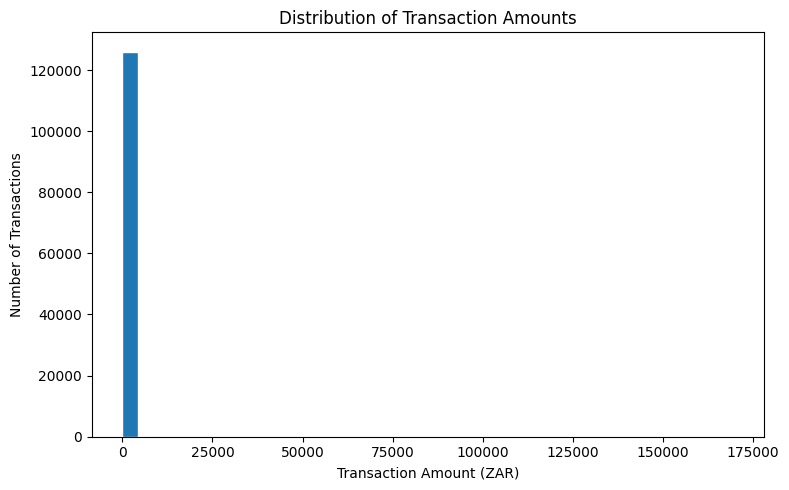

In [21]:
plt.figure()

amounts = plot_df["amount_zar"].dropna()

plt.hist(
    amounts,
    bins=40,
    edgecolor="white"
)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount (ZAR)")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

In [22]:
print(plot_df["amount_zar"].describe())
print("Unique amounts:", plot_df["amount_zar"].nunique())
print("First 10 amounts:")
print(plot_df["amount_zar"].head(10))

count    126370.000000
mean        203.717127
std         743.272347
min           0.040000
25%          30.520000
50%          69.490000
75%         159.060000
max      169505.510000
Name: amount_zar, dtype: float64
Unique amounts: 12476
First 10 amounts:
0    122.73
1    161.91
2    154.99
3    701.56
4    122.10
5    129.50
6    166.50
7     92.50
8    129.50
9      6.14
Name: amount_zar, dtype: float64


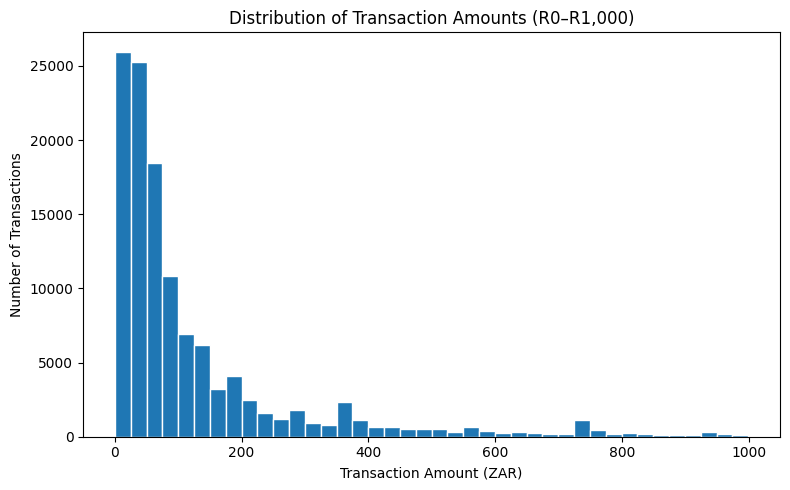

In [23]:
plt.figure()

amounts = plot_df["amount_zar"].dropna()
amounts = amounts[amounts <= 1000]

plt.hist(
    amounts,
    bins=40,
    edgecolor="white"
)

plt.title("Distribution of Transaction Amounts (R0–R1,000)")
plt.xlabel("Transaction Amount (ZAR)")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

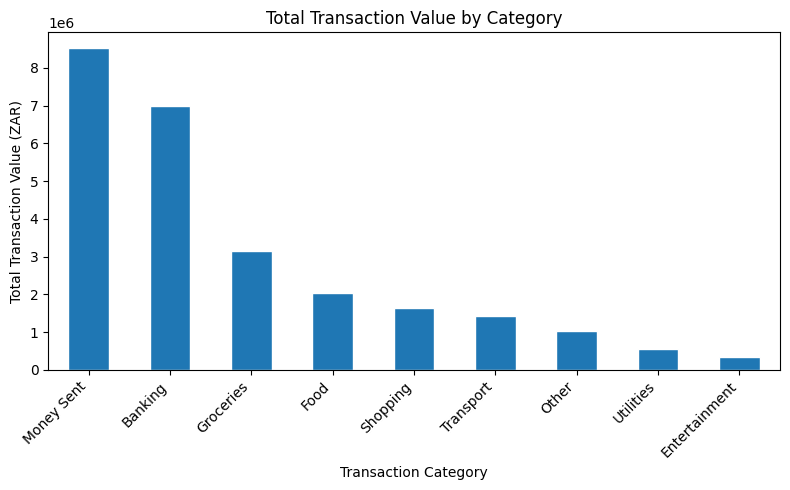

In [24]:
category_totals = (
    plot_df.groupby("category")["amount_zar"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure()

category_totals.plot(kind="bar", edgecolor="white")

plt.title("Total Transaction Value by Category")
plt.xlabel("Transaction Category")
plt.ylabel("Total Transaction Value (ZAR)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

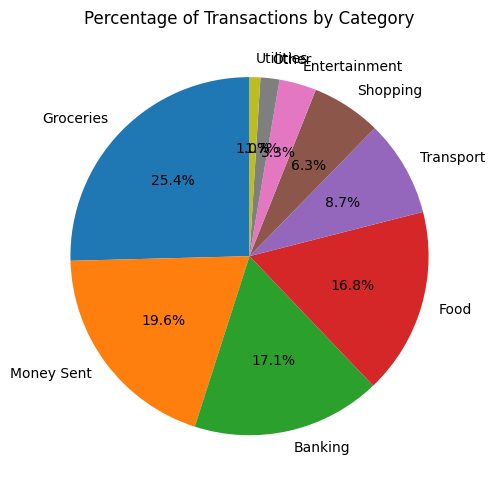

In [25]:
category_counts = plot_df["category"].value_counts()

plt.figure()

plt.pie(
    category_counts,
    labels=category_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage of Transactions by Category")
plt.tight_layout()
plt.show()

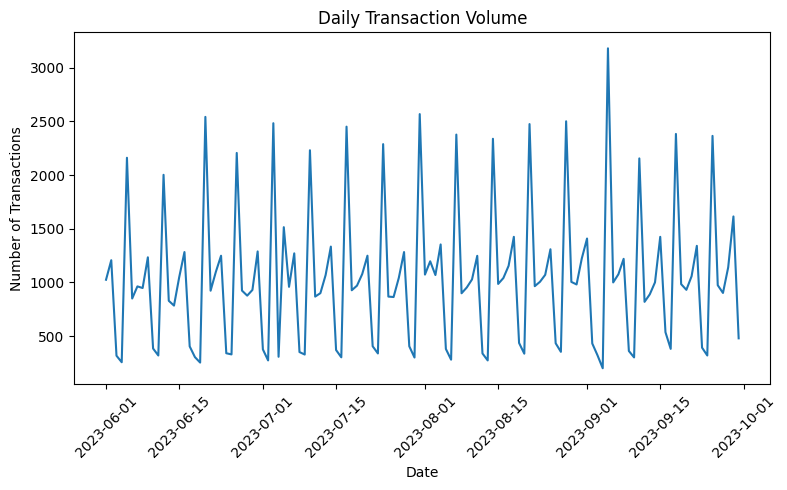

In [26]:
daily_transactions = (
    plot_df.groupby(plot_df["txn_date"].dt.date)
    .size()
)

plt.figure()

plt.plot(daily_transactions.index, daily_transactions.values)

plt.title("Daily Transaction Volume")
plt.xlabel("Date")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

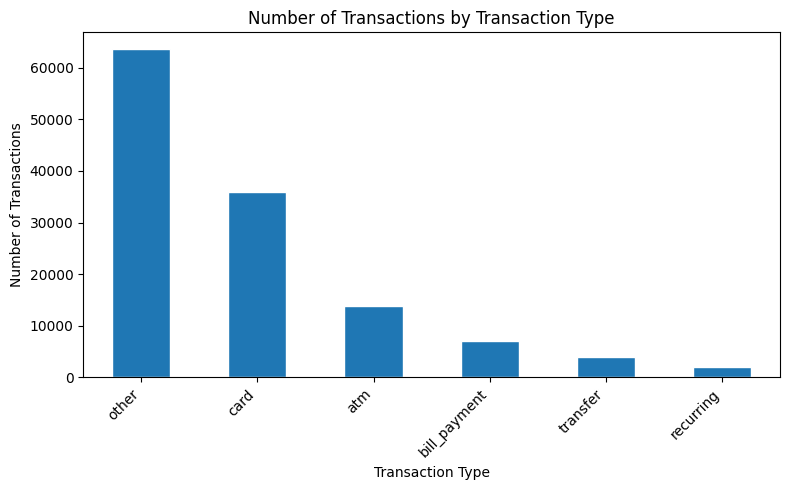

In [27]:
type_counts = plot_df["txn_type"].value_counts()

plt.figure()

type_counts.plot(kind="bar", edgecolor="white")

plt.title("Number of Transactions by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

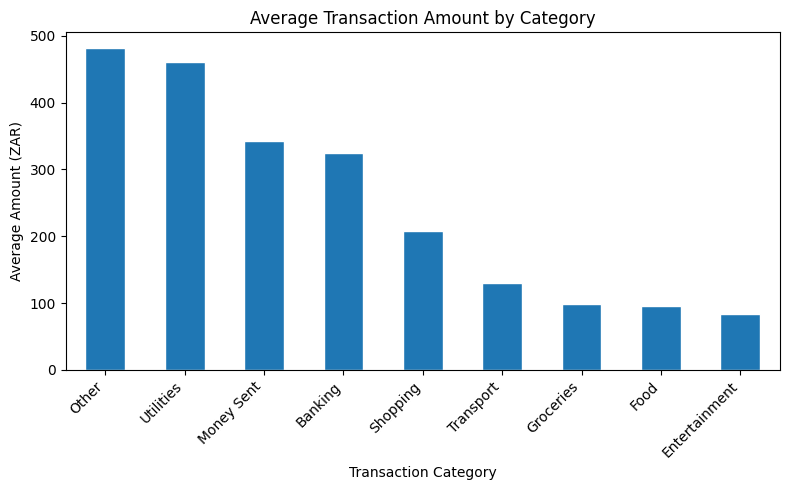

In [28]:
category_averages = (
    plot_df.groupby("category")["amount_zar"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure()

category_averages.plot(kind="bar", edgecolor="white")

plt.title("Average Transaction Amount by Category")
plt.xlabel("Transaction Category")
plt.ylabel("Average Amount (ZAR)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

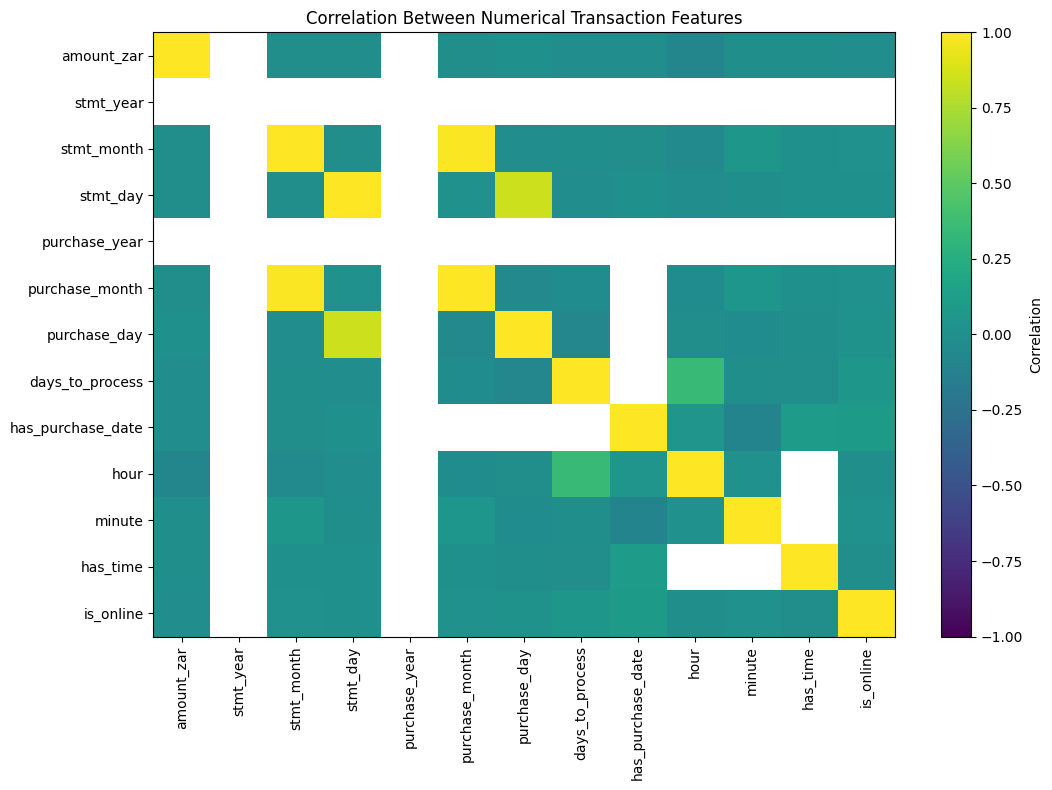

In [29]:
numeric_features = [
    "amount_zar",
    "stmt_year",
    "stmt_month",
    "stmt_day",
    "purchase_year",
    "purchase_month",
    "purchase_day",
    "days_to_process",
    "has_purchase_date",
    "hour",
    "minute",
    "has_time",
    "is_online"
]

correlation_matrix = plot_df[numeric_features].corr()

plt.figure(figsize=(11, 8))

plt.imshow(correlation_matrix, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(numeric_features)),
    numeric_features,
    rotation=90
)

plt.yticks(
    range(len(numeric_features)),
    numeric_features
)

plt.title("Correlation Between Numerical Transaction Features")
plt.tight_layout()
plt.show()

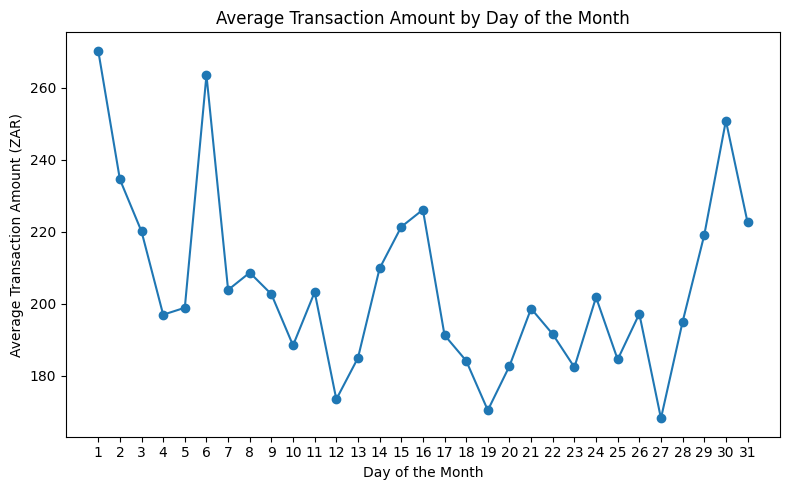

In [30]:
daily_averages = (
    plot_df.groupby("stmt_day")["amount_zar"]
    .mean()
    .sort_index()
)

plt.figure()

plt.plot(
    daily_averages.index,
    daily_averages.values,
    marker="o"
)

plt.title("Average Transaction Amount by Day of the Month")
plt.xlabel("Day of the Month")
plt.ylabel("Average Transaction Amount (ZAR)")
plt.xticks(range(1, 32))

plt.tight_layout()
plt.show()

# Rule-Based Insight Generator 

In [31]:

def generate_insights(transactions_df, category_col="predicted_category"):
    insights = []

    # Make sure transaction amounts are numeric
    data = transactions_df.copy()
    data["amount_zar"] = pd.to_numeric(
        data["amount_zar"], errors="coerce"
    )
    data = data.dropna(subset=[category_col, "amount_zar"])

    if data.empty:
        return ["There is not enough transaction data to generate insights."]

    # Rule 1: Identify the category with the highest total value
    category_totals = data.groupby(category_col)["amount_zar"].sum()
    top_category = category_totals.idxmax()
    top_total = category_totals.max()

    insights.append(
        f"Your highest total transaction value was in "
        f"{top_category} (R{top_total:,.2f})."
    )

    # Rule 2: Identify the most common transaction category
    category_counts = data[category_col].value_counts()
    common_category = category_counts.idxmax()
    common_count = category_counts.max()

    insights.append(
        f"{common_category} was your most frequent transaction category, "
        f"with {common_count} transactions."
    )

    # Rule 3: Calculate the average transaction amount
    average_amount = data["amount_zar"].mean()

    insights.append(
        f"Your average transaction amount was R{average_amount:,.2f}."
    )

    return insights


In [32]:
insights = generate_insights(pdf_features)

for insight in insights:
    print("•", insight)

• Your highest total transaction value was in Banking (R3,551.04).
• Groceries was your most frequent transaction category, with 16 transactions.
• Your average transaction amount was R185.99.


### Saving the model 

In [33]:
print("XGBoost model:", "xgb_model_D" in globals())
print("TF-IDF vectorizer:", "tfidf_D" in globals())
print("Imputer:", "imputer_D" in globals())
print("Scaler:", "scaler_D" in globals())
print("Label encoder:", "le" in globals())

XGBoost model: True
TF-IDF vectorizer: True
Imputer: True
Scaler: True
Label encoder: False


In [34]:
[name for name, obj in globals().items()
 if isinstance(obj, __import__("sklearn.preprocessing", fromlist=["LabelEncoder"]).LabelEncoder)]

['label_encoder_D']

In [35]:

import joblib
import sklearn
import xgboost
from pathlib import Path

# Bundle the trained model and its preprocessing components
finsight_model = {
    "model": xgb_model_D,
    "tfidf": tfidf_D,
    "imputer": imputer_D,
    "scaler": scaler_D,
    "label_encoder": label_encoder_D,
    "text_features": text_features_D,
    "numeric_features": numeric_features_D
}

# Save the complete model bundle
model_path = Path("finsight_model.joblib")
joblib.dump(finsight_model, model_path)

print("Model saved to:", model_path.resolve())
print(f"scikit-learn=={sklearn.__version__}")
print(f"xgboost=={xgboost.__version__}")


Model saved to: C:\Users\user\Finsight New\finsight_model.joblib
scikit-learn==1.8.0
xgboost==3.2.0


In [36]:

import joblib

# Load the saved model bundle
loaded_model = joblib.load("finsight_model.joblib")

# Check the saved components
print("Saved components:")
for component in loaded_model:
    print("-", component)

# Check the model
print("\nModel type:", type(loaded_model["model"]).__name__)
print("Categories:", loaded_model["label_encoder"].classes_)


Saved components:
- model
- tfidf
- imputer
- scaler
- label_encoder
- text_features
- numeric_features

Model type: XGBClassifier
Categories: ['Banking' 'Entertainment' 'Food' 'Groceries' 'Money Sent' 'Other'
 'Shopping' 'Transport' 'Utilities']


In [38]:

# Check which numerical features the model expects
print("Numerical features:")
print(loaded_model["numeric_features"])

print("\nNumber of numerical features:",
      len(loaded_model["numeric_features"]))

print("\nTF-IDF feature count:",
      len(loaded_model["tfidf"].get_feature_names_out()))

print("\nTotal features expected by XGBoost:",
      loaded_model["model"].n_features_in_)



Numerical features:
['amount_zar', 'stmt_year', 'stmt_month', 'stmt_day', 'purchase_year', 'purchase_month', 'purchase_day', 'days_to_process', 'has_purchase_date', 'hour', 'minute', 'has_time', 'is_online']

Number of numerical features: 13

TF-IDF feature count: 48409

Total features expected by XGBoost: 48422


In [39]:

import pandas as pd
from scipy.sparse import hstack

# 1. Create one test transaction
test_transaction = pd.DataFrame({
    "description_sa": ["WOOLWORTHS FOOD PURCHASE"],
    "amount_zar": [250.00],
    "stmt_year": [2023],
    "stmt_month": [9],
    "stmt_day": [15],
    "purchase_year": [2023],
    "purchase_month": [9],
    "purchase_day": [15],
    "days_to_process": [0],
    "has_purchase_date": [1],
    "hour": [12],
    "minute": [30],
    "has_time": [1],
    "is_online": [0]
})

# 2. Convert the description into TF-IDF features
text_input = loaded_model["tfidf"].transform(
    test_transaction["description_sa"]
)

# 3. Prepare the numerical features in the correct order
numeric_input = test_transaction[
    loaded_model["numeric_features"]
].copy()

numeric_input = loaded_model["imputer"].transform(numeric_input)
numeric_input = loaded_model["scaler"].transform(numeric_input)

# 4. Combine text and numerical features
from scipy.sparse import csr_matrix

combined_input = hstack([
    text_input,
    csr_matrix(numeric_input)
])

print("Input feature count:", combined_input.shape[1])
print("Expected feature count:", loaded_model["model"].n_features_in_)

# 5. Predict the category
prediction_encoded = loaded_model["model"].predict(combined_input)

prediction = loaded_model["label_encoder"].inverse_transform(
    prediction_encoded.astype(int)
)

print("\nTransaction:", test_transaction["description_sa"].iloc[0])
print("Predicted category:", prediction[0])


Input feature count: 48422
Expected feature count: 48422

Transaction: WOOLWORTHS FOOD PURCHASE
Predicted category: Groceries


In [40]:

import joblib

model_path = r"C:\Users\user\Finsight New\finsight_model.joblib"
bundle = joblib.load(model_path)

print("Text features:", bundle["text_features"])
print("Numerical features:", bundle["numeric_features"])
print("Model classes:", bundle["label_encoder"].classes_)


Text features: ['description_sa', 'txn_type']
Numerical features: ['amount_zar', 'stmt_year', 'stmt_month', 'stmt_day', 'purchase_year', 'purchase_month', 'purchase_day', 'days_to_process', 'has_purchase_date', 'hour', 'minute', 'has_time', 'is_online']
Model classes: ['Banking' 'Entertainment' 'Food' 'Groceries' 'Money Sent' 'Other'
 'Shopping' 'Transport' 'Utilities']


In [41]:
import json
print(json.dumps(json.load(open("model_metrics.json"))))

FileNotFoundError: [Errno 2] No such file or directory: 'model_metrics.json'